In [1]:

import glob
from joblib import Parallel, delayed
#from catalog_plotter import plot_var, get_array
import numpy as np
import plotter_config as pc
import sim_name_remap as map
import netCDF4 as nc4
import os
import datetime as dt
from scipy.interpolate import interp1d
import pickle as pkl
import matplotlib.tri as tri
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import datetime
from astropy.time import Time
import utils


In [2]:

sims = ['2022_E5-strong','2022_E5-weak','2022_M2-strong','2022_FreeRun']#'2022_M2-weak']  # This is only set up to do 4 at a time
date0 = '2022-08-18'
date1 = '2022-08-20'

var_lab = 'ZMMU'
plot_lev = 250.

#extent = [30,160,0,40]  # Anticylone box
extent = [110,160,25,55]
#extent = [105,145,25,45]  # August 19 box, full map boundaries
conv_dom = [110,122,36,42]   # Tiny box over the uplift region
#conv_dom = [105,145,25,45]   # The same as extent intentionally, to find max CO 
#conv_dom = [122,127,32,39]    # The Yellow Sea observation region

SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'


In [3]:

def get_simfield(sim, var_strs, date0, date1):

    sim_files = sorted(glob.glob(map.remap[sim]))
    
    sim_files0 = [item for item in sim_files if date0 in item][0]
    find0 = list(sim_files).index(sim_files0)
    sim_files1 = [item for item in sim_files if date1 in item][0]
    find1 = list(sim_files).index(sim_files1)
    
    sim_files = sim_files[find0:find1+1]

    # Crack open the first file and read the convective top information, then loop over the rest
    sim_nc = nc4.Dataset(sim_files[0])
    simlon = sim_nc.variables['lon'][:]
    simlat = sim_nc.variables['lat'][:]
    hyam = sim_nc.variables['hyam'][:]
    hybm = sim_nc.variables['hybm'][:]
    date = sim_nc.variables['date'][:]
    datesec = sim_nc.variables['datesec'][:]
    simfield = sim_nc.variables[var_strs[0]][:]
    if len(var_strs) > 1: 
        for v in range(len(var_strs)-1):
            curr_simfield = sim_nc.variables[var_strs[v+1]][:]
            simfield = simfield + curr_simfield
    
    for f in sim_files[1:]:
        sim_nc = nc4.Dataset(f)        
        date = np.append(date, sim_nc.variables['date'][:])
        datesec = np.append(datesec, sim_nc.variables['datesec'][:])
        
        simfield_f = sim_nc.variables[var_strs[0]][:]
        if len(var_strs) > 1: 
            for v in range(len(var_strs)-1):
                curr_simfield_f = sim_nc.variables[var_strs[v+1]][:]
                simfield_f = simfield_f + curr_simfield_f                
        simfield = np.append(simfield, simfield_f, axis=0)
    
    print('Simulated field shape = ', np.shape(simfield))

    return simfield, simlon, simlat, hyam, hybm, np.asarray(date).flatten(), np.asarray(datesec).flatten()

# This subroutine will interpolate an unstructured variable field (dimensions of lev x pt) to a specific pressure level 
# with help from the model pressure field (dimension of lev x pt, units of Pa)

def interp_to_prslev(var_arr, PS_arr, lon, lat, hyam, hybm, plot_lev, var_name):

    #print('Interpolating ' + var_name + ' to the ' + str(plot_lev) + 'hPa surface at ' + valid_datestr)

    var_plev = np.zeros((len(lat), len(lon)))-999

    for ln in range(len(lon)):
        for lt in range(len(lat)):

            curr_PS = PS_arr[lt,ln]
            curr_plev = (hyam*1.0e5 + hybm*curr_PS)/100.  

            plev_f = interp1d(curr_plev, np.squeeze(var_arr[:,lt,ln]), bounds_error=False, fill_value=-999)

            var_plev[lt,ln] = plev_f(plot_lev)
    
    return var_plev

def moving_window_smooth(data, width=1):
    data_copy = np.copy(data)
    smoothed = np.zeros(data_copy.shape)
    for ix in range(data_copy.shape[0]):
        for iy in range(data_copy.shape[1]):
            smoothed[ix,iy] = np.nanmean(data_copy[ix-width:ix+width,iy-width:iy+width])
    return smoothed    

def draw_box(ax, left, right, bot, top, col, thk):
    ax.plot([left, left], [bot, top], color=col, linewidth=thk)
    ax.plot([right, right], [bot, top], color=col, linewidth=thk)
    ax.plot([left, right], [bot, bot], color=col, linewidth=thk)
    ax.plot([left, right], [top, top], color=col, linewidth=thk) 
    

In [4]:

def get_ACCLIP_merge_data(OBSROOT, FLT_DATES, var_str):
    
    OBSvar = []

    for FLT_DATE in FLT_DATES:
    
        AIRFILE = glob.glob(OBSROOT + '*' + FLT_DATE + '*.ict')[0]     
        AIRheaders = np.loadtxt(AIRFILE, delimiter=',', usecols = (0), dtype='str')
        AIRdata = np.loadtxt(AIRFILE, delimiter=',', skiprows=int(AIRheaders[0]))  # Read the file
        OBSvar.extend(AIRdata[:,int(list(AIRheaders).index(var_str))-11])
        
    return np.asarray(OBSvar)
    
def calc_max(lon, lat, var_plot, var_name, plot_lev, sim, extent, conv_dom):

    #GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'
    #GV_FLT_DATES = ['20220806']
    #ACCLIP_GV_lon = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLON') 
    #ACCLIP_GV_lat = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLAT')     

    #WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'
    #WB_FLT_DATES = ['20220819']
    #ACCLIP_WB_lon = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LONG_MMS') 
    #ACCLIP_WB_lat = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LAT_MMS') 
    
    #ax.set_extent(extent)

    #ax.coastlines()
    #ax.set_title(var_name + ' at ' + str(plot_lev) + 'hPa on ' + valid_datestr)
    #ax.set_title(sim)
    
    #cbar_lev, cbar_rgb, norm = utils.get_colorbar(var_name, plot_lev, 0)  # 0 standard, 1 weird, 2 reds

    #cf = ax.contourf(lon, lat, var_plot, levels=cbar_lev, norm=norm, cmap=cbar_rgb, extend='both')

    #ax.scatter(ACCLIP_GV_lon, ACCLIP_GV_lat, s=0.5, color='k')
    #ax.scatter(ACCLIP_WB_lon, ACCLIP_WB_lat, s=0.5, color='k') 

    # Put a cross at the location where var_plot is maximized on the plot

    # Smooth first
    #var_plot_sm = moving_window_smooth(var_plot, width=1)
    
    i = np.where((lon >= conv_dom[0]) & (lon <= conv_dom[1]))[0]
    j = np.where((lat >= conv_dom[2]) & (lat <= conv_dom[3]))[0]
    var_sub = var_plot[np.ix_(j,i)]
    jj,ii = np.unravel_index(var_sub.argmax(), var_sub.shape)
    varmax_lonind = i[ii]
    varmax_latind = j[jj]
    
    #ax.scatter([lon[varmax_lonind]], [lat[varmax_latind]], marker='+', color='blue', s=50)

    #draw_box(ax, conv_dom[0], conv_dom[1], conv_dom[2], conv_dom[3], 'magenta', 1)

    return varmax_lonind, varmax_latind, var_plot[varmax_latind,varmax_lonind]   #, cbar_lev

def plot_prof(ax, varprof, PS, varstr, sim, SAVEFILE, xlim=[0,400]):

    plev = (hyam*1.0e5 + hybm*PS)/100. 

    ax.plot(varprof, plev)
    ax.set_xlim(xlim)
    ax.set_ylim(1000,50)
    ax.set_yscale('log')
    ax.set_xlabel(varstr + '(' + pc.var_info[varstr]['unit'] + ')')
    ax.set_ylabel('Pressure (hPa)')
    ax.set_title(sim)

    with open(SAVEFILE, 'wb') as f:
        pkl.dump((varprof, plev), f)


In [5]:

var_strs = pc.var_info[var_lab]['vars']

# Read the model variables
simvar0, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[0], var_strs, date0, date1)
simvar1, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[1], var_strs, date0, date1)
simvar2, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[2], var_strs, date0, date1)
simvar3, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[3], var_strs, date0, date1)

simPS0, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[0], ['PS'], date0, date1)
simPS1, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[1], ['PS'], date0, date1)
simPS2, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[2], ['PS'], date0, date1)
simPS3, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[3], ['PS'], date0, date1)

# For profiles, we also read in ZMMU and CO fields here
simZMMU0, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[0], ['ZMMU'], date0, date1)
simZMMU1, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[1], ['ZMMU'], date0, date1)
simZMMU2, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[2], ['ZMMU'], date0, date1)
simZMMU3, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[3], ['ZMMU'], date0, date1)

simCO0, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[0], ['CO'], date0, date1)
simCO1, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[1], ['CO'], date0, date1)
simCO2, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[2], ['CO'], date0, date1)
simCO3, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[3], ['CO'], date0, date1)

simT0, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[0], ['T'], date0, date1)
simT1, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[1], ['T'], date0, date1)
simT2, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[2], ['T'], date0, date1)
simT3, lon, lat, hyam, hybm, date, datesec = get_simfield(sims[3], ['T'], date0, date1)


Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 192, 288)
Simulated field shape =  (24, 192, 288)
Simulated field shape =  (24, 192, 288)
Simulated field shape =  (24, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)
Simulated field shape =  (24, 32, 192, 288)


In [6]:

jd_arr = []
varmax_convdom0 = []
varmax_convdom1 = []
varmax_convdom2 = []
varmax_convdom3 = []

# Interpolate to the desired pressure level and plot, one time step at a time
for t in range(np.shape(simvar0)[0]):
#for t in range(2):

    datestr = str(date[t]) + '_' + str(int(datesec[t]/3600.)).zfill(2) + 'Z'     #_' + str(int((datesec[t]/60.) % 60)).zfill(2) + 'min'
    dt = datetime.datetime(int(str(date[t])[0:4]), int(str(date[t])[4:6]), int(str(date[t])[6:8])) + datetime.timedelta(seconds=int(datesec[t]))
    jd_arr.append(Time(dt, scale='utc').jd)
    
    print('Plotting at ', datestr)

    if len(np.shape(simvar0)) == 4: 
        simvar0_plot = interp_to_prslev(np.squeeze(simvar0[t,:,:,:]), np.squeeze(simPS0[t,:,:]), lon, lat, hyam, hybm, plot_lev, var_lab)*pc.var_info[var_lab]['mod']
        simvar1_plot = interp_to_prslev(np.squeeze(simvar1[t,:,:,:]), np.squeeze(simPS1[t,:,:]), lon, lat, hyam, hybm, plot_lev, var_lab)*pc.var_info[var_lab]['mod']
        simvar2_plot = interp_to_prslev(np.squeeze(simvar2[t,:,:,:]), np.squeeze(simPS2[t,:,:]), lon, lat, hyam, hybm, plot_lev, var_lab)*pc.var_info[var_lab]['mod']
        simvar3_plot = interp_to_prslev(np.squeeze(simvar3[t,:,:,:]), np.squeeze(simPS3[t,:,:]), lon, lat, hyam, hybm, plot_lev, var_lab)*pc.var_info[var_lab]['mod']
    if len(np.shape(simvar0)) == 3: 
        simvar0_plot = np.squeeze(simvar0[t,:,:])*pc.var_info[var_lab]['mod']
        simvar1_plot = np.squeeze(simvar1[t,:,:])*pc.var_info[var_lab]['mod']
        simvar2_plot = np.squeeze(simvar2[t,:,:])*pc.var_info[var_lab]['mod']
        simvar3_plot = np.squeeze(simvar3[t,:,:])*pc.var_info[var_lab]['mod']
    
    fig = plt.figure(figsize=(14,10))
    ax0 = fig.add_subplot(2,2,1,projection=ccrs.PlateCarree())
    ax1 = fig.add_subplot(2,2,2,projection=ccrs.PlateCarree())
    ax2 = fig.add_subplot(2,2,3,projection=ccrs.PlateCarree())
    ax3 = fig.add_subplot(2,2,4,projection=ccrs.PlateCarree())

    varmax_lonind0, varmax_latind0, varmax0 = calc_max(lon, lat, simvar0_plot, var_lab, plot_lev, sims[0], extent, conv_dom)
    varmax_lonind1, varmax_latind1, varmax1 = calc_max(lon, lat, simvar1_plot, var_lab, plot_lev, sims[1], extent, conv_dom)
    varmax_lonind2, varmax_latind2, varmax2 = calc_max(lon, lat, simvar2_plot, var_lab, plot_lev, sims[2], extent, conv_dom)
    varmax_lonind3, varmax_latind3, varmax3 = calc_max(lon, lat, simvar3_plot, var_lab, plot_lev, sims[3], extent, conv_dom)

    varmax_convdom0.append(varmax0)
    varmax_convdom1.append(varmax1)
    varmax_convdom2.append(varmax2)
    varmax_convdom3.append(varmax3)
    
    #cbax = fig.add_axes([0.91,0.3,0.02,0.4])
    #cbar = plt.colorbar(cf, cax=cbax, orientation='vertical', ticks = cbar_lev[::4])
    #cbar.set_label(var_lab + '(' + pc.var_info[var_lab]['unit'] + ')')
    #
    #plt.figtext(0.43,0.48,var_lab + ' at ' + str(plot_lev) + ' hPa on ' + datestr)
    #
    #plt.savefig('/glade/u/home/wsmith/ASM_Plotter/plots/' + var_lab + '_multi-model_' + datestr + '.png')
    #plt.close('all')

    # Next, make profiles at the maximum plot field location

    # First CO 
    
    fig = plt.figure(figsize=(10,10))
    ax0 = fig.add_subplot(2,2,1)
    ax1 = fig.add_subplot(2,2,2)
    ax2 = fig.add_subplot(2,2,3)
    ax3 = fig.add_subplot(2,2,4)

    plot_prof(ax0, np.squeeze(simCO0[t,:,varmax_latind0,varmax_lonind0])*1e9, np.squeeze(simPS0[t,varmax_latind0,varmax_lonind0]), 'CO',\
              sims[0], SAVEDIR + sims[0] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxCOprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,250])
    plot_prof(ax1, np.squeeze(simCO1[t,:,varmax_latind1,varmax_lonind1])*1e9, np.squeeze(simPS1[t,varmax_latind1,varmax_lonind1]), 'CO',\
              sims[1], SAVEDIR + sims[1] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxCOprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,250])
    plot_prof(ax2, np.squeeze(simCO2[t,:,varmax_latind2,varmax_lonind2])*1e9, np.squeeze(simPS2[t,varmax_latind2,varmax_lonind2]), 'CO',\
              sims[2], SAVEDIR + sims[2] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxCOprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,250])
    plot_prof(ax3, np.squeeze(simCO3[t,:,varmax_latind3,varmax_lonind3])*1e9, np.squeeze(simPS3[t,varmax_latind3,varmax_lonind3]), 'CO',\
              sims[3], SAVEDIR + sims[3] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxCOprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,250])
    
    plt.figtext(0.43,0.48,datestr)
    plt.savefig('/glade/u/home/wsmith/ASM_Plotter/plots/' + var_lab + '_maxCOprofs_multimodel' + datestr + '.png')
    plt.close('all')
    
    # Also ZMMU
    
    fig = plt.figure(figsize=(10,10))
    ax0 = fig.add_subplot(2,2,1)
    ax1 = fig.add_subplot(2,2,2)
    ax2 = fig.add_subplot(2,2,3)
    ax3 = fig.add_subplot(2,2,4)

    plot_prof(ax0, np.squeeze(simZMMU0[t,:,varmax_latind0,varmax_lonind0])*3600, np.squeeze(simPS0[t,varmax_latind0,varmax_lonind0]), 'ZMMU',\
              sims[0], SAVEDIR + sims[0] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxZMMUprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,350])
    plot_prof(ax1, np.squeeze(simZMMU1[t,:,varmax_latind1,varmax_lonind1])*3600, np.squeeze(simPS1[t,varmax_latind1,varmax_lonind1]), 'ZMMU',\
              sims[1], SAVEDIR + sims[1] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxZMMUprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,350])
    plot_prof(ax2, np.squeeze(simZMMU2[t,:,varmax_latind2,varmax_lonind2])*3600, np.squeeze(simPS2[t,varmax_latind2,varmax_lonind2]), 'ZMMU',\
              sims[2], SAVEDIR + sims[2] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxZMMUprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,350])
    plot_prof(ax3, np.squeeze(simZMMU3[t,:,varmax_latind3,varmax_lonind3])*3600, np.squeeze(simPS3[t,varmax_latind3,varmax_lonind3]), 'ZMMU',\
              sims[3], SAVEDIR + sims[3] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxZMMUprof_' + str(conv_dom) + '_' + datestr + '.pkl', xlim=[0,350])
    
    plt.figtext(0.43,0.48,datestr)
    plt.savefig('/glade/u/home/wsmith/ASM_Plotter/plots/' + var_lab + '_maxZMMUprofs_multimodel' + datestr + '.png')
    plt.close('all')

    # Temperature profiles

    fig = plt.figure(figsize=(6,6))
    ax0 = fig.add_subplot(1,1,1)

    plevsim0 = (hyam*1.0e5 + hybm*simPS0[t,varmax_latind0,varmax_lonind0])/100.
    plevsim1 = (hyam*1.0e5 + hybm*simPS1[t,varmax_latind1,varmax_lonind1])/100.

    ax0.plot(simT0[t,:,varmax_latind0,varmax_lonind0], plevsim0, color='red', label=sims[0])
    ax0.plot(simT1[t,:,varmax_latind1,varmax_lonind1], plevsim1, color='blue', label=sims[1])    
    ax0.set_yscale('log')
    ax0.set_ylim(1000,100)

    ax0.set_title('Temperature profiles at location of max ' + var_lab + ' at ' + datestr)
    ax0.set_xlabel('Temperature (K)')
    ax0.set_ylabel('Pressure (hPa)')

    plt.legend()

    plt.savefig('/glade/u/home/wsmith/ASM_Plotter/plots/' + var_lab + '_Tprofs_multimodel' + datestr + '.png')
    plt.close('all')



Plotting at  20220818_03Z
Plotting at  20220818_06Z
Plotting at  20220818_09Z
Plotting at  20220818_12Z
Plotting at  20220818_15Z
Plotting at  20220818_18Z
Plotting at  20220818_21Z
Plotting at  20220819_00Z
Plotting at  20220819_03Z
Plotting at  20220819_06Z
Plotting at  20220819_09Z
Plotting at  20220819_12Z
Plotting at  20220819_15Z
Plotting at  20220819_18Z
Plotting at  20220819_21Z
Plotting at  20220820_00Z
Plotting at  20220820_03Z
Plotting at  20220820_06Z
Plotting at  20220820_09Z
Plotting at  20220820_12Z
Plotting at  20220820_15Z
Plotting at  20220820_18Z
Plotting at  20220820_21Z
Plotting at  20220821_00Z


In [7]:

# Save a time series of the maximum var value within the convective domain (calculated in the t loop above)

with open(SAVEDIR + sims[0] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxval_' + str(conv_dom) + '_' + date0 + '-' + str(date1) + '.pkl', 'wb') as f:
    pkl.dump((jd_arr, varmax_convdom0), f)

with open(SAVEDIR + sims[1] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxval_' + str(conv_dom) + '_' + date0 + '-' + str(date1) + '.pkl', 'wb') as f:
    pkl.dump((jd_arr, varmax_convdom1), f)

with open(SAVEDIR + sims[2] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxval_' + str(conv_dom) + '_' + date0 + '-' + str(date1) + '.pkl', 'wb') as f:
    pkl.dump((jd_arr, varmax_convdom2), f)

with open(SAVEDIR + sims[3] + '_' + var_lab + '_' + str(int(plot_lev)) + '_maxval_' + str(conv_dom) + '_' + date0 + '-' + str(date1) + '.pkl', 'wb') as f:
    pkl.dump((jd_arr, varmax_convdom3), f)


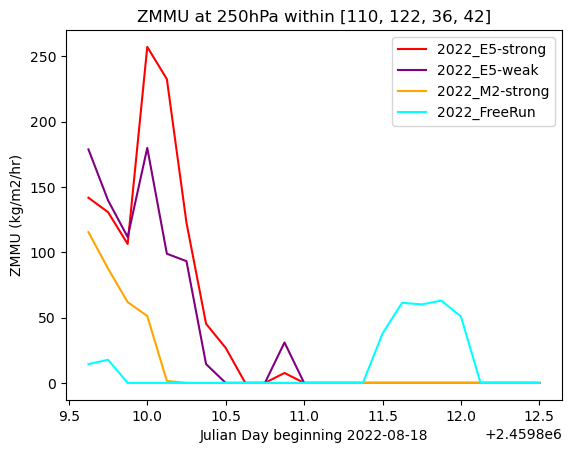

In [8]:

# Also make a quick preview time series plot of the saved info above because you're cool like that

plt.plot(jd_arr, varmax_convdom0, label=sims[0], color='red')
plt.plot(jd_arr, varmax_convdom1, label=sims[1], color='purple')
plt.plot(jd_arr, varmax_convdom2, label=sims[2], color='orange')
plt.plot(jd_arr, varmax_convdom3, label=sims[3], color='cyan')
plt.legend()
plt.xlabel('Julian Day beginning ' + date0)
plt.ylabel(var_lab + ' (' + pc.var_info[var_lab]['unit'] + ')')
plt.title(var_lab + ' at ' + str(int(plot_lev)) + 'hPa within ' + str(conv_dom))
if var_lab == 'CO': plt.ylim(50,420)
